In [3]:
# You will need to install the `matplotlib` python package
import matplotlib.pyplot as plt
from   matplotlib        import rc
import pandas            as pd
from   mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

plt.style.use("ggplot") # This defines an aesthetic style

In [4]:
# This is a common dataset about Iris flowers
remote_data = '../data/IRIS.csv'
df  = pd.read_csv(remote_data, header=0, index_col=None)
odf = df.copy()
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
95,7.2,3.0,5.8,1.6,virginica
96,7.4,2.8,6.1,1.9,virginica
97,7.9,3.8,6.4,2.0,virginica
98,6.4,2.8,5.6,2.2,virginica


In [28]:
# Add a column to the dataframe about that is an integer-represented version of the 
# `species column. For example where species == 'setosa', the new column should be 0
# and where species == 'virginica' the new colum should would be 1
species = sorted(list(set(df['species'])))
odf['species_int'] = df['species'].apply(lambda x: species.index(x)) 
odf.drop_duplicates(subset='species')

,sepal_length,sepal_width,petal_length,petal_width,species,species_int
0,5.1,3.5,1.4,0.2,setosa,0
32,7.0,3.2,4.7,1.4,versicolor,1
66,6.3,3.3,6.0,2.5,virginica,2


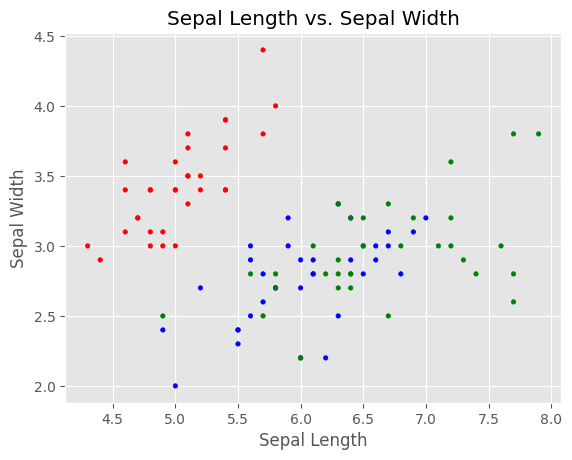

In [29]:
# Create a scatter plot with Sepal Length, Sepal Width on the spatial dimensions
#  and colored points for the species.
# You may want to create a integer-type column for species

# If you use the integer species column (which has values 0 - 2) you can index this
# array of color names:
mycolors = ['red','blue','green']

plt.figure()
plt.scatter(
    odf['sepal_length'],
    odf['sepal_width'],
    s = 10,
    c = [mycolors[i] for i in odf['species_int']])
plt.title('Sepal Length vs. Sepal Width')
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.show()

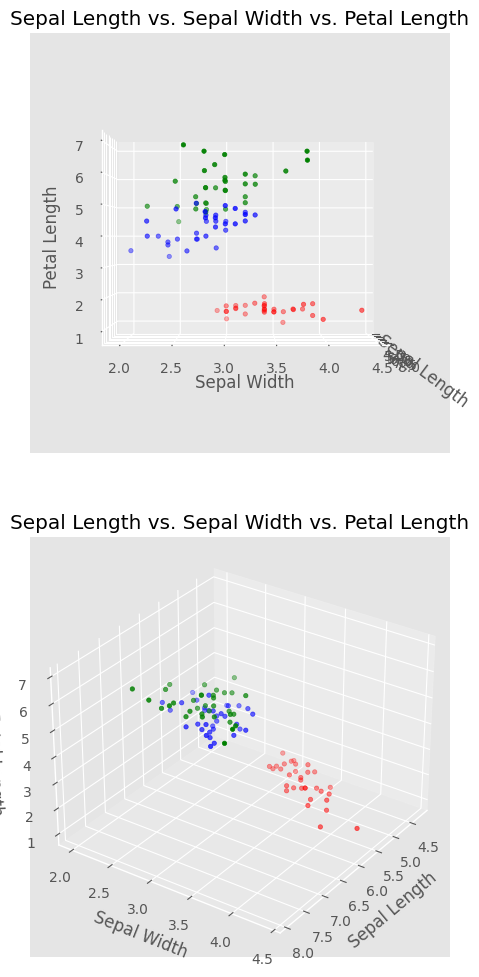

In [82]:
# But there are a lot more than two dimensions (+ species) in the data
# Let's try a 3D plot with matplotlib.
# See https://matplotlib.org/mpl_toolkits/mplot3d/tutorial.html
# Create a 3D scatter plot of the sepal width , sepal length and petal length
# You can pass a color vector like you (hopefully) did with 2D scatter()

# You also may want to render the same plot from different angles.

from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12,12))
for i in range(0,2):
    ax = fig.add_subplot(2,1,i+1, projection='3d')
    ax.scatter(
        odf['sepal_length'],
        odf['sepal_width'],
        odf['petal_length'],
        s = 10,
        c = [mycolors[i] for i in odf['species_int']])

    ax.view_init(elev=i*30, azim=i*35)
    ax.set_title('Sepal Length vs. Sepal Width vs. Petal Length')
    ax.set_xlabel('Sepal Length')
    ax.set_ylabel('Sepal Width')
    ax.set_zlabel('Petal Length')

plt.show()


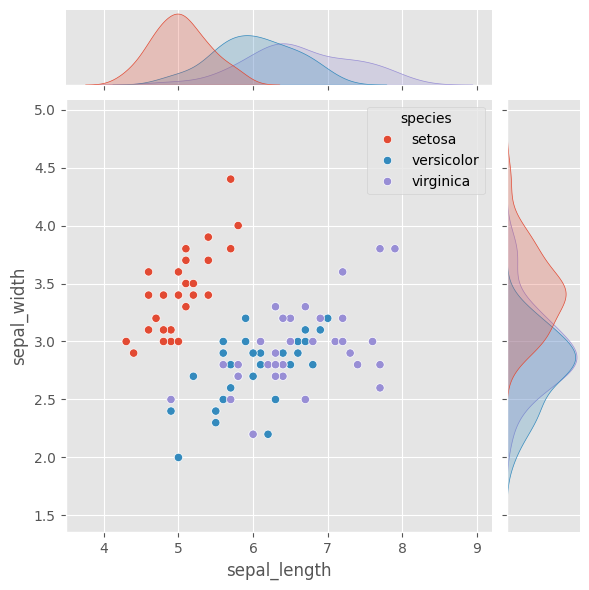

In [83]:
# Use the Seaborn package (https://seaborn.pydata.org/) `pip install seaborn`
#  to visualize joint distributions between sepal and petal properties
# Specifically, use the jointplot() function to visualize petal properties
# Note that this function may take a few seconds to run.
import seaborn as sns

sns.jointplot(
    data = odf,
    x="sepal_length",
    y="sepal_width",
    kind = "scatter",
    hue = "species")

plt.show()

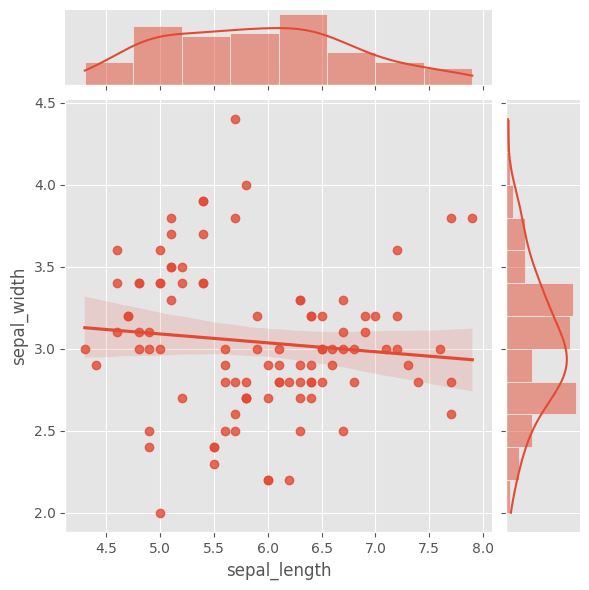

In [74]:
# Question: adding the argument kind='reg' adds information to the plot. 
#           looking at the documentation, what is this information?

# kind{ “scatter” | “kde” | “hist” | “hex” | “reg” | “resid” }
# Kind of plot to draw. See the examples for references to the underlying functions.
# Set kind="reg" to add a linear regression fit (using regplot()) and univariate KDE curves

sns.jointplot(
    data = odf,
    x="sepal_length",
    y="sepal_width",
    kind = "reg")

plt.show()

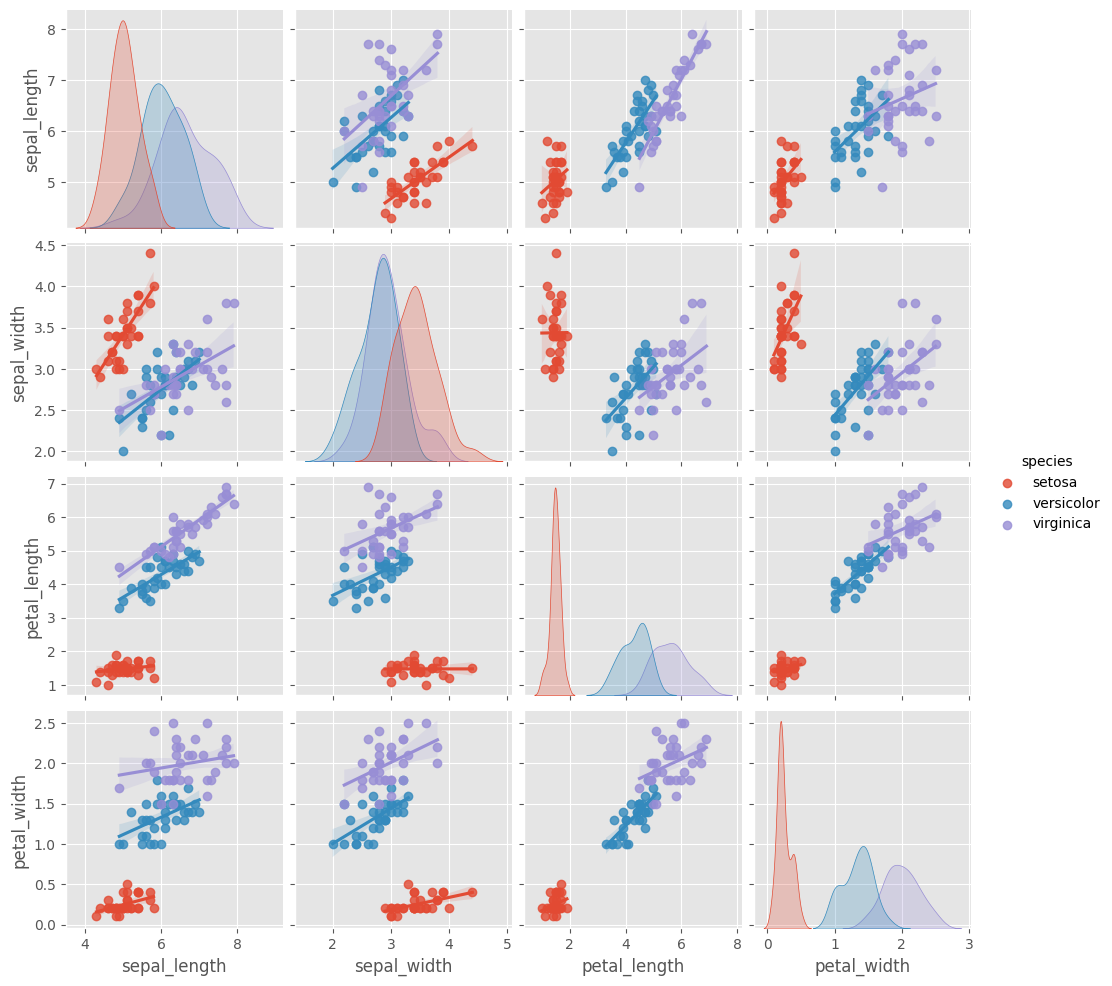

In [80]:
# Use seaborn's pairplot() function to plot All The Dimensions at once.
# You may want to use the original dataframe (without the integer species column)
# without the added columns

# Try adding kind='reg',diag_kind='kde' to pairplot()
# Which representation do you like better? why?
sns.pairplot(
    df,
    hue = 'species',
    kind = 'reg')

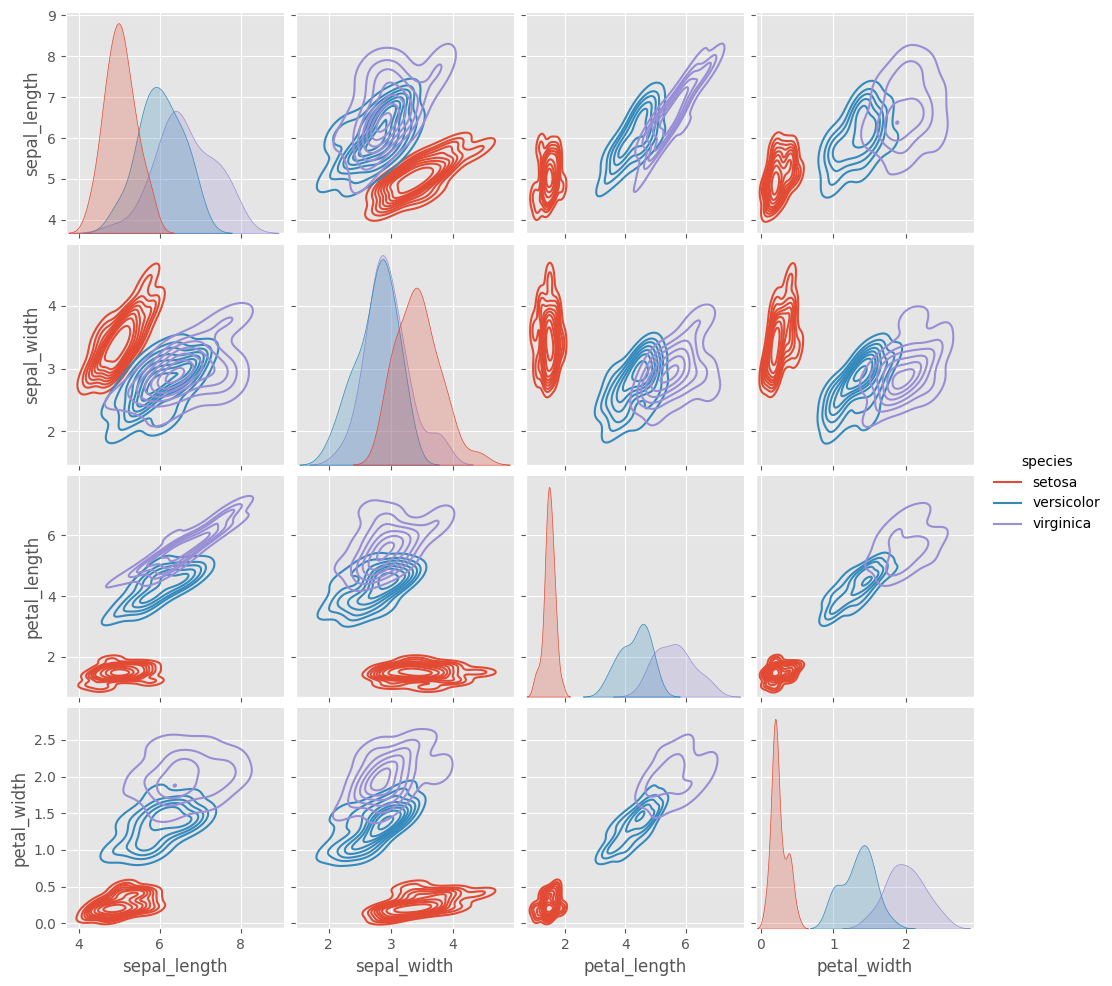

In [79]:
sns.pairplot(
    df,
    hue = 'species',
    kind = 'kde')

In [81]:
# I like kde because it's clearly showing the areas convered by the different lengths 